In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU available nahi hai. Runtime settings check karein.")

PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [2]:
!pip -q install nibabel timm scikit-learn matplotlib pandas tqdm

In [3]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
from pathlib import Path

DATA_DIR = Path(
    "/content/drive/MyDrive/Colab Notebooks/Data Set/ADNI dataset"
)

print("Dataset path exists:", DATA_DIR.exists())

for class_name in ["AD", "MCI", "CN"]:
    folder = DATA_DIR / class_name

    print(f"\n{class_name} folder exists:", folder.exists())

    if folder.exists():
        nii_files = list(folder.glob("*.nii.gz"))
        print(f"{class_name} MRI files:", len(nii_files))

Dataset path exists: True

AD folder exists: True
AD MRI files: 0

MCI folder exists: True
MCI MRI files: 0

CN folder exists: True
CN MRI files: 0


In [6]:
from pathlib import Path

for class_name in ["AD", "MCI", "CN"]:
    folder = DATA_DIR / class_name

    print(f"\n{'=' * 40}")
    print(f"Folder: {class_name}")

    # Show the first 15 items directly inside the folder
    items = list(folder.iterdir())

    print("Total items:", len(items))

    for item in items[:15]:
        print(item.name, "|", "Folder" if item.is_dir() else "File")

    # Search recursively for MRI files
    nii_files = list(folder.rglob("*.nii.gz"))
    nii_files += list(folder.rglob("*.nii"))

    print("MRI files found recursively:", len(nii_files))


Folder: AD
Total items: 1
AD_converted | Folder
MRI files found recursively: 718

Folder: MCI
Total items: 1
MCI_converted | Folder
MRI files found recursively: 1466

Folder: CN
Total items: 1
CN_converted | Folder
MRI files found recursively: 1571


File name: ADNI_MPRAGE_20070807113640_2.nii.gz
MRI shape: (160, 240, 256)
Voxel spacing: (np.float32(1.2), np.float32(1.0), np.float32(1.0))
Minimum intensity: 0.0
Maximum intensity: 3206.0


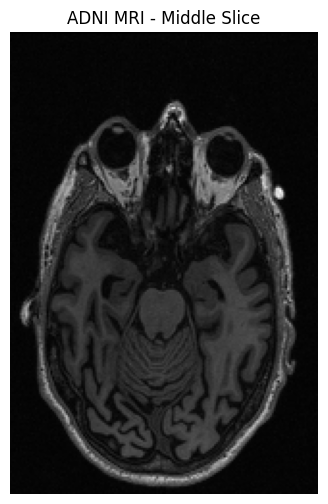

In [7]:
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt

# Find one MRI file inside the AD folder and its subfolders
sample_files = list((DATA_DIR / "AD").rglob("*.nii.gz"))

if not sample_files:
    sample_files = list((DATA_DIR / "AD").rglob("*.nii"))

sample_file = sample_files[0]

# Load the MRI volume
img = nib.load(str(sample_file))
volume = img.get_fdata(dtype=np.float32)

print("File name:", sample_file.name)
print("MRI shape:", volume.shape)
print("Voxel spacing:", img.header.get_zooms()[:3])
print("Minimum intensity:", np.min(volume))
print("Maximum intensity:", np.max(volume))

# Display the middle slice
middle_slice = volume[:, :, volume.shape[2] // 2]

plt.figure(figsize=(6, 6))
plt.imshow(middle_slice.T, cmap="gray", origin="lower")
plt.title("ADNI MRI - Middle Slice")
plt.axis("off")
plt.show()

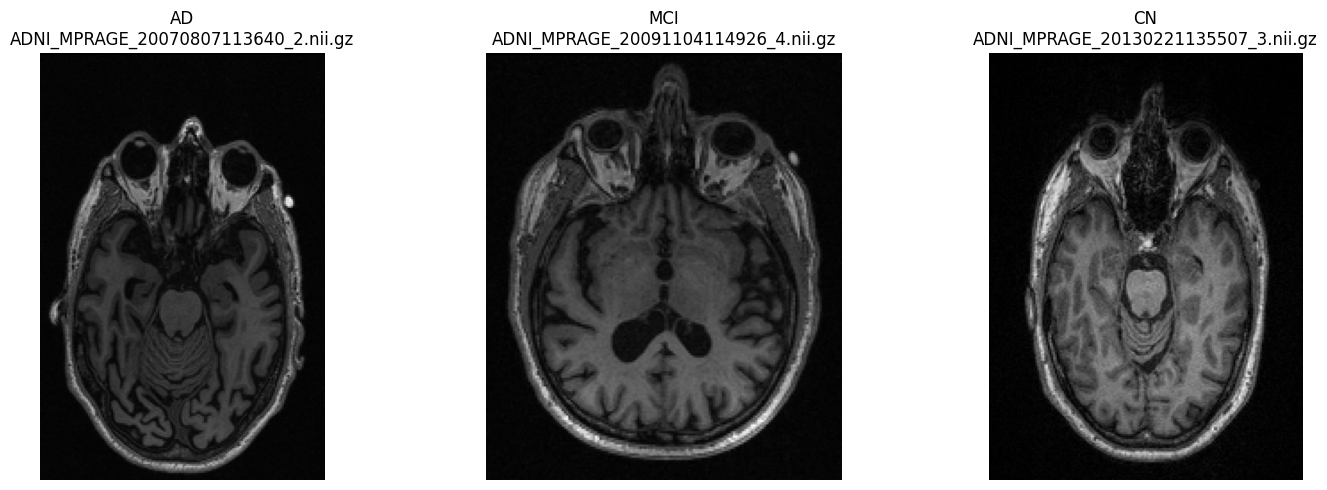

In [8]:
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt

classes = ["AD", "MCI", "CN"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, class_name in zip(axes, classes):
    folder = DATA_DIR / class_name

    files = list(folder.rglob("*.nii.gz"))
    if not files:
        files = list(folder.rglob("*.nii"))

    if not files:
        ax.set_title(f"{class_name}: No MRI found")
        ax.axis("off")
        continue

    img = nib.load(str(files[0]))
    volume = img.get_fdata(dtype=np.float32)

    middle_slice = volume[:, :, volume.shape[2] // 2]

    ax.imshow(middle_slice.T, cmap="gray", origin="lower")
    ax.set_title(f"{class_name}\n{files[0].name}")
    ax.axis("off")

    del volume, img

plt.tight_layout()
plt.show()


Original intensity range: 0.0 to 1739.0
Normalization limits: 23.0 to 960.6100000000006
Normalized intensity range: 0.0 to 1.0


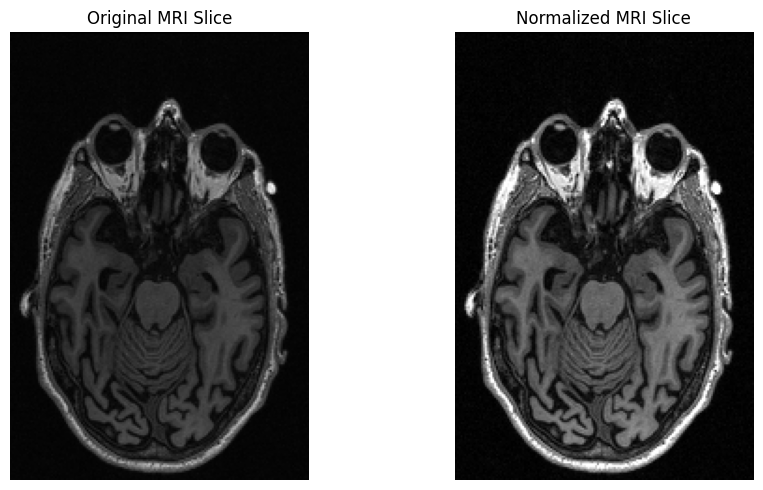

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import nibabel as nib

# Select one MRI from the AD folder
sample_file = list((DATA_DIR / "AD").rglob("*.nii.gz"))[0]

img = nib.load(str(sample_file))
volume = img.get_fdata(dtype=np.float32)

# Extract the middle slice
mri_slice = volume[:, :, volume.shape[2] // 2]

# Normalize using the 1st and 99th intensity percentiles
nonzero = mri_slice[mri_slice > 0]

if nonzero.size > 0:
    low, high = np.percentile(nonzero, [1, 99])
else:
    low, high = 0, 1

if high > low:
    normalized_slice = np.clip(
        (mri_slice - low) / (high - low), 0, 1
    )
else:
    normalized_slice = np.zeros_like(mri_slice)

print("Original intensity range:", mri_slice.min(), "to", mri_slice.max())
print("Normalization limits:", low, "to", high)
print("Normalized intensity range:", normalized_slice.min(), "to", normalized_slice.max())

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(mri_slice.T, cmap="gray", origin="lower")
plt.title("Original MRI Slice")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(normalized_slice.T, cmap="gray", origin="lower", vmin=0, vmax=1)
plt.title("Normalized MRI Slice")
plt.axis("off")

plt.tight_layout()
plt.show()

Original slice size: (240, 160)
Resized image size: (224, 224)


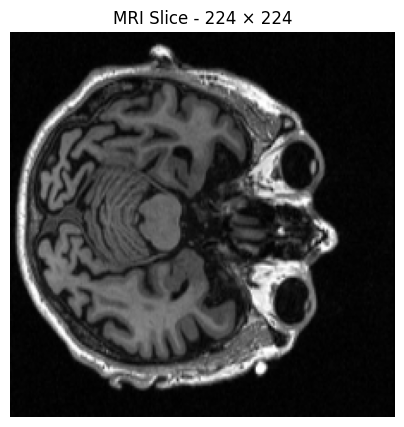

In [10]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

IMG_SIZE = 224

# Convert normalized MRI slice to an 8-bit image
image_array = (normalized_slice * 255).astype(np.uint8)

mri_image = Image.fromarray(image_array)

# Resize image
resized_image = mri_image.resize(
    (IMG_SIZE, IMG_SIZE),
    Image.Resampling.BILINEAR
)

print("Original slice size:", mri_image.size)
print("Resized image size:", resized_image.size)

plt.figure(figsize=(5, 5))
plt.imshow(resized_image, cmap="gray")
plt.title("MRI Slice - 224 × 224")
plt.axis("off")
plt.show()

In [11]:
from pathlib import Path
from PIL import Image
import nibabel as nib
import numpy as np
from tqdm.auto import tqdm
import gc

# Temporary output folder in Colab
OUTPUT_DIR = Path("/content/ADNI_2D")
CLASSES = ["AD", "MCI", "CN"]
IMG_SIZE = 224

for class_name in CLASSES:
    (OUTPUT_DIR / class_name).mkdir(parents=True, exist_ok=True)

def preprocess_mri_file(file_path, output_path):
    img = nib.load(str(file_path))
    volume = img.get_fdata(dtype=np.float32)

    if volume.ndim != 3:
        return False

    # Select the middle slice
    mri_slice = volume[:, :, volume.shape[2] // 2]

    # Normalize non-zero intensities
    nonzero = mri_slice[mri_slice > 0]

    if nonzero.size == 0:
        return False

    low, high = np.percentile(nonzero, [1, 99])

    if high <= low:
        return False

    normalized = np.clip((mri_slice - low) / (high - low), 0, 1)

    # Convert and resize
    image = Image.fromarray((normalized * 255).astype(np.uint8))
    image = image.resize(
        (IMG_SIZE, IMG_SIZE),
        Image.Resampling.BILINEAR
    )
    image.save(output_path)

    del volume, img, image
    return True

for class_name in CLASSES:
    source_folder = DATA_DIR / class_name
    output_folder = OUTPUT_DIR / class_name

    files = list(source_folder.rglob("*.nii.gz"))
    files += list(source_folder.rglob("*.nii"))

    print(f"\nProcessing {class_name}: {len(files)} MRI files")

    success = 0
    failed = 0

    for file_path in tqdm(files, desc=class_name):
        # Keep a distinct output name for each MRI
        output_name = file_path.name.replace(".nii.gz", ".png").replace(".nii", ".png")
        output_path = output_folder / output_name

        if output_path.exists():
            success += 1
            continue

        try:
            if preprocess_mri_file(file_path, output_path):
                success += 1
            else:
                failed += 1
        except Exception as e:
            failed += 1
            print(f"\nCould not process {file_path.name}: {e}")

    print(f"{class_name}: processed={success}, failed={failed}")
    gc.collect()

print("\nPreprocessing finished.")
print("Output directory:", OUTPUT_DIR)


Processing AD: 718 MRI files


AD:   0%|          | 0/718 [00:00<?, ?it/s]

AD: processed=718, failed=0

Processing MCI: 1466 MRI files


MCI:   0%|          | 0/1466 [00:00<?, ?it/s]

MCI: processed=1466, failed=0

Processing CN: 1571 MRI files


CN:   0%|          | 0/1571 [00:00<?, ?it/s]

CN: processed=1571, failed=0

Preprocessing finished.
Output directory: /content/ADNI_2D


AD: 718 images
MCI: 1466 images
CN: 1571 images


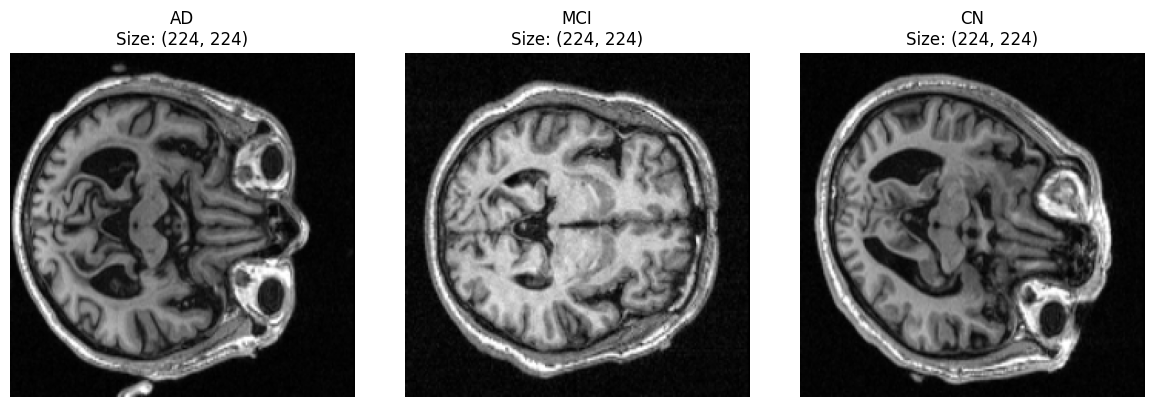

In [12]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

OUTPUT_DIR = Path("/content/ADNI_2D")
CLASSES = ["AD", "MCI", "CN"]

for class_name in CLASSES:
    files = sorted((OUTPUT_DIR / class_name).glob("*.png"))
    print(f"{class_name}: {len(files)} images")

# Display one processed image from each class
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, class_name in zip(axes, CLASSES):
    files = sorted((OUTPUT_DIR / class_name).glob("*.png"))

    if files:
        image = Image.open(files[0])
        ax.imshow(image, cmap="gray")
        ax.set_title(f"{class_name}\nSize: {image.size}")
    else:
        ax.set_title(f"{class_name}: No images")

    ax.axis("off")

plt.tight_layout()
plt.show()

In [13]:
import numpy as np
from pathlib import Path
from sklearn.model_selection import train_test_split
from collections import Counter

OUTPUT_DIR = Path("/content/ADNI_2D")
CLASSES = ["CN", "MCI", "AD"]

class_to_idx = {"CN": 0, "MCI": 1, "AD": 2}
idx_to_class = {0: "CN", 1: "MCI", 2: "AD"}

all_paths = []
all_labels = []

for class_name in CLASSES:
    image_files = sorted((OUTPUT_DIR / class_name).glob("*.png"))

    all_paths.extend([str(path) for path in image_files])
    all_labels.extend([class_to_idx[class_name]] * len(image_files))

all_paths = np.array(all_paths)
all_labels = np.array(all_labels)

# 70% training, 30% remaining
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    all_paths,
    all_labels,
    test_size=0.30,
    random_state=42,
    stratify=all_labels
)

# Split remaining 30% equally into validation and test
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    random_state=42,
    stratify=temp_labels
)

print("Total images:", len(all_paths))
print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Testing images:", len(test_paths))

print("\nTraining class counts:")
print({idx_to_class[k]: v for k, v in Counter(train_labels).items()})

print("\nValidation class counts:")
print({idx_to_class[k]: v for k, v in Counter(val_labels).items()})

print("\nTesting class counts:")
print({idx_to_class[k]: v for k, v in Counter(test_labels).items()})

Total images: 3755
Training images: 2628
Validation images: 563
Testing images: 564

Training class counts:
{'CN': 1099, 'MCI': 1026, 'AD': 503}

Validation class counts:
{'CN': 236, 'MCI': 220, 'AD': 107}

Testing class counts:
{'MCI': 220, 'CN': 236, 'AD': 108}


In [14]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

BATCH_SIZE = 8
NUM_WORKERS = 2

# Training augmentation and normalization
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ToTensor(),
    transforms.Lambda(lambda x: x.repeat(3, 1, 1)),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Validation and testing: no random augmentation
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Lambda(lambda x: x.repeat(3, 1, 1)),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class MRIDataset(Dataset):
    def __init__(self, paths, labels, transform=None):
        self.paths = list(paths)
        self.labels = list(labels)
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        image = Image.open(self.paths[index]).convert("L")

        if self.transform:
            image = self.transform(image)

        label = int(self.labels[index])
        return image, label

train_dataset = MRIDataset(
    train_paths, train_labels, train_transform
)

val_dataset = MRIDataset(
    val_paths, val_labels, eval_transform
)

test_dataset = MRIDataset(
    test_paths, test_labels, eval_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

# Verify one batch
images, labels = next(iter(train_loader))

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Sample labels:", labels.tolist())

Training batches: 329
Validation batches: 71
Testing batches: 71
Image batch shape: torch.Size([8, 3, 224, 224])
Label batch shape: torch.Size([8])
Sample labels: [0, 2, 1, 1, 1, 0, 1, 0]


In [15]:
import torch
import timm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

# CNN branch: EfficientNet-B4
cnn_branch = timm.create_model(
    "efficientnet_b4",
    pretrained=True,
    num_classes=0
)

# Transformer branch: Vision Transformer B/16
vit_branch = timm.create_model(
    "vit_base_patch16_224",
    pretrained=True,
    num_classes=0
)

# Check feature dimensions
cnn_branch.eval()
vit_branch.eval()

with torch.no_grad():
    dummy_input = torch.randn(1, 3, 224, 224)

    cnn_features = cnn_branch(dummy_input)
    vit_features = vit_branch(dummy_input)

print("EfficientNet-B4 feature shape:", cnn_features.shape)
print("ViT-B/16 feature shape:", vit_features.shape)

Using device: cuda


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


model.safetensors: reconstructing file:   0%|          |  0.00B / 77.9MB            

model.safetensors: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

EfficientNet-B4 feature shape: torch.Size([1, 1792])
ViT-B/16 feature shape: torch.Size([1, 768])


In [16]:
import torch
import torch.nn as nn

class HybridCNNViT(nn.Module):
    def __init__(self, cnn, vit):
        super().__init__()

        self.cnn = cnn
        self.vit = vit

        self.classifier = nn.Sequential(
            nn.Linear(1792 + 768, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, 3)
        )

    def forward(self, x):
        cnn_features = self.cnn(x)
        vit_features = self.vit(x)

        # Combine CNN and Transformer features
        fused_features = torch.cat(
            [cnn_features, vit_features],
            dim=1
        )

        output = self.classifier(fused_features)
        return output


model = HybridCNNViT(
    cnn=cnn_branch,
    vit=vit_branch
).to(device)

print("Hybrid model created successfully!")
print("Device:", device)
print("Total parameters:", f"{sum(p.numel() for p in model.parameters()):,}")
print("Trainable parameters:", f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

Hybrid model created successfully!
Device: cuda
Total parameters: 104,660,043
Trainable parameters: 104,660,043


In [17]:
import torch
import torch.nn as nn
import torch.optim as optim

# Loss function for 3-class classification
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

# Training settings
EPOCHS = 5
best_val_accuracy = 0.0

# Save the best model temporarily
MODEL_PATH = "/content/best_hybrid_cnn_vit.pth"

# Mixed precision helps reduce GPU memory usage on the T4
scaler = torch.amp.GradScaler("cuda")

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", optimizer.param_groups[0]["lr"])
print("Epochs:", EPOCHS)
print("GPU:", torch.cuda.get_device_name(0))
print("Training setup ready!")

Loss function: CrossEntropyLoss()
Optimizer: AdamW
Learning rate: 0.0001
Epochs: 5
GPU: Tesla T4
Training setup ready!


In [18]:

from sklearn.metrics import accuracy_score
import torch
from tqdm.auto import tqdm

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

for epoch in range(EPOCHS):
    # Training
    model.train()
    train_loss_total = 0.0
    train_correct = 0
    train_total = 0

    train_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS} - Training")

    for images, labels in train_bar:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        batch_size = labels.size(0)
        train_loss_total += loss.item() * batch_size
        train_correct += (outputs.argmax(dim=1) == labels).sum().item()
        train_total += batch_size

        train_bar.set_postfix(loss=f"{loss.item():.4f}")

    train_loss = train_loss_total / train_total
    train_accuracy = train_correct / train_total

    # Validation
    model.eval()
    val_loss_total = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in tqdm(
            val_loader, desc=f"Epoch {epoch+1}/{EPOCHS} - Validation"
        ):
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=(device.type == "cuda")
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)

            batch_size = labels.size(0)
            val_loss_total += loss.item() * batch_size
            val_correct += (outputs.argmax(dim=1) == labels).sum().item()
            val_total += batch_size

    val_loss = val_loss_total / val_total
    val_accuracy = val_correct / val_total

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    print(f"\nEpoch {epoch+1}/{EPOCHS}")
    print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_accuracy:.4f}")
    print(f"Val Loss:   {val_loss:.4f} | Val Accuracy:   {val_accuracy:.4f}")

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "class_to_idx": class_to_idx,
                "epoch": epoch + 1,
                "val_accuracy": val_accuracy
            },
            MODEL_PATH
        )
        print(f"Best model saved: {MODEL_PATH}")

print(f"\nTraining completed. Best validation accuracy: {best_val_accuracy:.4f}")


Epoch 1/5 - Training:   0%|          | 0/329 [00:00<?, ?it/s]

Epoch 1/5 - Validation:   0%|          | 0/71 [00:00<?, ?it/s]


Epoch 1/5
Train Loss: 1.0503 | Train Accuracy: 0.4593
Val Loss:   0.9981 | Val Accuracy:   0.5488
Best model saved: /content/best_hybrid_cnn_vit.pth


Epoch 2/5 - Training:   0%|          | 0/329 [00:00<?, ?it/s]

Epoch 2/5 - Validation:   0%|          | 0/71 [00:00<?, ?it/s]

...


Epoch 4/5
Train Loss: 0.8548 | Train Accuracy: 0.6058
Val Loss:   0.8741 | Val Accuracy:   0.5666


Epoch 5/5 - Training:   0%|          | 0/329 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b6d773158a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b6d773158a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 5/5 - Validation:   0%|          | 0/71 [00:00<?, ?it/s]


Epoch 5/5
Train Loss: 0.7540 | Train Accuracy: 0.6511
Val Loss:   0.8764 | Val Accuracy:   0.5915
Best model saved: /content/best_hybrid_cnn_vit.pth

Training completed. Best validation accuracy: 0.5915


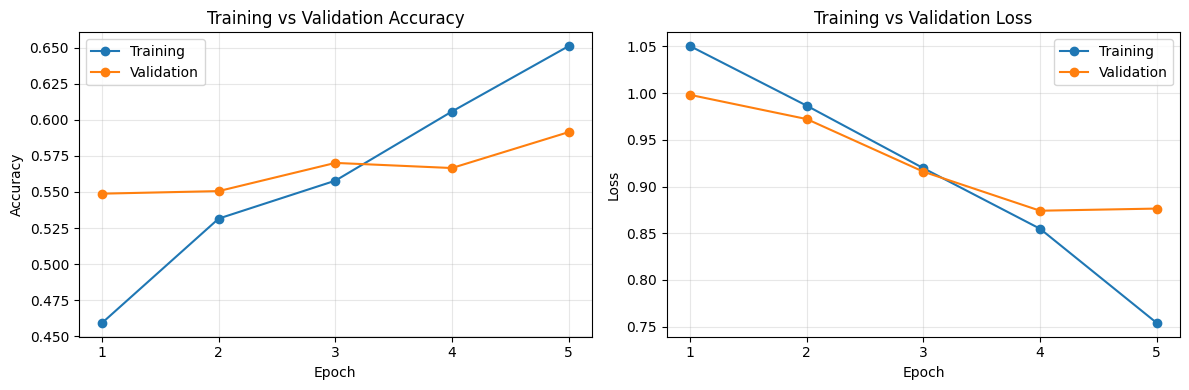

In [19]:

import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, history["train_accuracy"], marker="o", label="Training")
plt.plot(epochs, history["val_accuracy"], marker="o", label="Validation")
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(list(epochs))
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epochs, history["train_loss"], marker="o", label="Training")
plt.plot(epochs, history["val_loss"], marker="o", label="Validation")
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(list(epochs))
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [20]:

import torch
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Load the best saved Hybrid CNN-ViT checkpoint
checkpoint = torch.load(MODEL_PATH, map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):
            outputs = model(images)

        predictions = outputs.argmax(dim=1).cpu().numpy()
        y_pred.extend(predictions)
        y_true.extend(labels.numpy())

hybrid_test_accuracy = accuracy_score(y_true, y_pred)

print(f"Hybrid CNN-ViT Test Accuracy: {hybrid_test_accuracy * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2],
    target_names=["CN", "MCI", "AD"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred, labels=[0, 1, 2]))


Hybrid CNN-ViT Test Accuracy: 60.64%

Classification Report:
              precision    recall  f1-score   support

          CN       0.67      0.61      0.64       236
         MCI       0.57      0.69      0.63       220
          AD       0.55      0.43      0.48       108

    accuracy                           0.61       564
   macro avg       0.60      0.58      0.58       564
weighted avg       0.61      0.61      0.60       564

Confusion Matrix:
[[144  72  20]
 [ 50 152  18]
 [ 21  41  46]]


In [21]:

import timm
import torch
import torch.nn as nn

# Create standalone EfficientNet-B4 for 3-class classification
efficientnet_model = timm.create_model(
    "efficientnet_b4",
    pretrained=True,
    num_classes=3
).to(device)

print("EfficientNet-B4 loaded successfully.")
print("Device:", device)
print("Number of classes:", 3)
print("Classes:", idx_to_class)
print("Ready for fine-tuning.")


EfficientNet-B4 loaded successfully.
Device: cuda
Number of classes: 3
Classes: {0: 'CN', 1: 'MCI', 2: 'AD'}
Ready for fine-tuning.


In [22]:

import torch
import torch.nn as nn
import torch.optim as optim
from tqdm.auto import tqdm

efficientnet_criterion = nn.CrossEntropyLoss()

efficientnet_optimizer = optim.AdamW(
    efficientnet_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

efficientnet_scaler = torch.amp.GradScaler("cuda")
EFFICIENTNET_EPOCHS = 5
efficientnet_best_val_accuracy = 0.0

EFFICIENTNET_PATH = "/content/best_efficientnet_b4.pth"

efficientnet_history = {
    "train_accuracy": [],
    "val_accuracy": [],
    "train_loss": [],
    "val_loss": []
}

for epoch in range(EFFICIENTNET_EPOCHS):
    efficientnet_model.train()
    train_loss_sum, train_correct, train_total = 0.0, 0, 0

    for images, labels in tqdm(
        train_loader, desc=f"EfficientNet Epoch {epoch+1}/5"
    ):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        efficientnet_optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            outputs = efficientnet_model(images)
            loss = efficientnet_criterion(outputs, labels)

        efficientnet_scaler.scale(loss).backward()
        efficientnet_scaler.step(efficientnet_optimizer)
        efficientnet_scaler.update()

        n = labels.size(0)
        train_loss_sum += loss.item() * n
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += n

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    efficientnet_model.eval()
    val_loss_sum, val_correct, val_total = 0.0, 0, 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.autocast(device_type="cuda", dtype=torch.float16):
                outputs = efficientnet_model(images)
                loss = efficientnet_criterion(outputs, labels)

            n = labels.size(0)
            val_loss_sum += loss.item() * n
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += n

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    efficientnet_history["train_loss"].append(train_loss)
    efficientnet_history["train_accuracy"].append(train_acc)
    efficientnet_history["val_loss"].append(val_loss)
    efficientnet_history["val_accuracy"].append(val_acc)

    print(f"\nEpoch {epoch+1}/5")
    print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc*100:.2f}%")
    print(f"Val Loss:   {val_loss:.4f} | Val Accuracy:   {val_acc*100:.2f}%")

    if val_acc > efficientnet_best_val_accuracy:
        efficientnet_best_val_accuracy = val_acc
        torch.save(efficientnet_model.state_dict(), EFFICIENTNET_PATH)
        print("Best EfficientNet-B4 checkpoint saved.")

print(
    f"\nBest EfficientNet-B4 validation accuracy: "
    f"{efficientnet_best_val_accuracy*100:.2f}%"
)


EfficientNet Epoch 1/5:   0%|          | 0/329 [00:00<?, ?it/s]


Epoch 1/5
Train Loss: 1.3593 | Train Accuracy: 44.25%
Val Loss:   1.1595 | Val Accuracy:   48.67%
Best EfficientNet-B4 checkpoint saved.


EfficientNet Epoch 2/5:   0%|          | 0/329 [00:00<?, ?it/s]


Epoch 2/5
Train Loss: 1.0813 | Train Accuracy: 49.43%
Val Loss:   1.0546 | Val Accuracy:   48.31%


EfficientNet Epoch 3/5:   0%|          | 0/329 [00:00<?, ?it/s]


Epoch 3/5
Train Loss: 0.9662 | Train Accuracy: 54.45%
Val Loss:   0.9984 | Val Accuracy:   51.15%
Best EfficientNet-B4 checkpoint saved.


EfficientNet Epoch 4/5:   0%|          | 0/329 [00:00<?, ?it/s]


Epoch 4/5
Train Loss: 0.8948 | Train Accuracy: 58.22%
Val Loss:   0.9746 | Val Accuracy:   55.77%
Best EfficientNet-B4 checkpoint saved.


EfficientNet Epoch 5/5:   0%|          | 0/329 [00:00<?, ?it/s]


Epoch 5/5
Train Loss: 0.8407 | Train Accuracy: 61.83%
Val Loss:   0.9665 | Val Accuracy:   56.66%
Best EfficientNet-B4 checkpoint saved.

Best EfficientNet-B4 validation accuracy: 56.66%


In [23]:

import torch
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Load the best EfficientNet-B4 checkpoint
efficientnet_model.load_state_dict(
    torch.load(EFFICIENTNET_PATH, map_location=device)
)
efficientnet_model.eval()

efficientnet_y_true = []
efficientnet_y_pred = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):
            outputs = efficientnet_model(images)

        efficientnet_y_pred.extend(
            outputs.argmax(dim=1).cpu().numpy()
        )
        efficientnet_y_true.extend(labels.numpy())

efficientnet_test_accuracy = accuracy_score(
    efficientnet_y_true,
    efficientnet_y_pred
)

print(
    f"EfficientNet-B4 Test Accuracy: "
    f"{efficientnet_test_accuracy * 100:.2f}%"
)

print("\nClassification Report:")
print(classification_report(
    efficientnet_y_true,
    efficientnet_y_pred,
    labels=[0, 1, 2],
    target_names=["CN", "MCI", "AD"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(
    efficientnet_y_true,
    efficientnet_y_pred,
    labels=[0, 1, 2]
))

# Store results for the final comparison
model_results = globals().get("model_results", {})
model_results["Hybrid CNN-ViT"] = 60.64
model_results["EfficientNet-B4"] = efficientnet_test_accuracy * 100

print("\nCurrent model comparison:")
for name, accuracy in model_results.items():
    print(f"{name}: {accuracy:.2f}%")


EfficientNet-B4 Test Accuracy: 57.45%

Classification Report:
              precision    recall  f1-score   support

          CN       0.64      0.62      0.63       236
         MCI       0.52      0.70      0.60       220
          AD       0.55      0.20      0.30       108

    accuracy                           0.57       564
   macro avg       0.57      0.51      0.51       564
weighted avg       0.58      0.57      0.56       564

Confusion Matrix:
[[147  86   3]
 [ 50 155  15]
 [ 31  55  22]]

Current model comparison:
Hybrid CNN-ViT: 60.64%
EfficientNet-B4: 57.45%


In [24]:

import timm
import torch
import torch.nn as nn
import torch.optim as optim

vit_model = timm.create_model(
    "vit_base_patch16_224",
    pretrained=True,
    num_classes=3
).to(device)

vit_criterion = nn.CrossEntropyLoss()

vit_optimizer = optim.AdamW(
    vit_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

vit_scaler = torch.amp.GradScaler("cuda")
VIT_PATH = "/content/best_vit_b16.pth"
VIT_EPOCHS = 5
vit_best_val_accuracy = 0.0

vit_history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

print("ViT-B/16 loaded successfully.")
print(f"Device: {device}")
print(f"Trainable parameters: {sum(p.numel() for p in vit_model.parameters() if p.requires_grad):,}")
print("Ready for training.")


ViT-B/16 loaded successfully.
Device: cuda
Trainable parameters: 85,800,963
Ready for training.


In [25]:

from tqdm.auto import tqdm

for epoch in range(VIT_EPOCHS):
    vit_model.train()
    train_loss_sum, train_correct, train_total = 0.0, 0, 0

    for images, labels in tqdm(
        train_loader, desc=f"ViT Epoch {epoch+1}/{VIT_EPOCHS}"
    ):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        vit_optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):
            outputs = vit_model(images)
            loss = vit_criterion(outputs, labels)

        vit_scaler.scale(loss).backward()
        vit_scaler.step(vit_optimizer)
        vit_scaler.update()

        n = labels.size(0)
        train_loss_sum += loss.item() * n
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += n

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    vit_model.eval()
    val_loss_sum, val_correct, val_total = 0.0, 0, 0

    with torch.no_grad():
        for images, labels in tqdm(
            val_loader, desc=f"ViT Validation {epoch+1}/{VIT_EPOCHS}"
        ):
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=(device.type == "cuda")
            ):
                outputs = vit_model(images)
                loss = vit_criterion(outputs, labels)

            n = labels.size(0)
            val_loss_sum += loss.item() * n
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += n

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    vit_history["train_loss"].append(train_loss)
    vit_history["train_accuracy"].append(train_acc)
    vit_history["val_loss"].append(val_loss)
    vit_history["val_accuracy"].append(val_acc)

    print(f"\nEpoch {epoch+1}/{VIT_EPOCHS}")
    print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc*100:.2f}%")
    print(f"Val Loss:   {val_loss:.4f} | Val Accuracy:   {val_acc*100:.2f}%")

    if val_acc > vit_best_val_accuracy:
        vit_best_val_accuracy = val_acc
        torch.save(vit_model.state_dict(), VIT_PATH)
        print("Best ViT-B/16 checkpoint saved.")

print(f"\nBest ViT-B/16 validation accuracy: {vit_best_val_accuracy*100:.2f}%")


ViT Epoch 1/5:   0%|          | 0/329 [00:00<?, ?it/s]

ViT Validation 1/5:   0%|          | 0/71 [00:00<?, ?it/s]


Epoch 1/5
Train Loss: 1.1131 | Train Accuracy: 41.17%
Val Loss:   1.0689 | Val Accuracy:   46.71%
Best ViT-B/16 checkpoint saved.


ViT Epoch 2/5:   0%|          | 0/329 [00:00<?, ?it/s]

ViT Validation 2/5:   0%|          | 0/71 [00:00<?, ?it/s]

...


Epoch 4/5
Train Loss: 1.0564 | Train Accuracy: 44.60%
Val Loss:   1.0564 | Val Accuracy:   39.08%


ViT Epoch 5/5:   0%|          | 0/329 [00:00<?, ?it/s]

ViT Validation 5/5:   0%|          | 0/71 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b6d773158a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b6d773158a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/


Epoch 5/5
Train Loss: 1.0365 | Train Accuracy: 46.99%
Val Loss:   1.0957 | Val Accuracy:   45.47%

Best ViT-B/16 validation accuracy: 50.27%


In [26]:

import torch
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load the best ViT-B/16 checkpoint
vit_model.load_state_dict(torch.load(VIT_PATH, map_location=device))
vit_model.eval()

vit_y_true = []
vit_y_pred = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):
            outputs = vit_model(images)

        vit_y_pred.extend(outputs.argmax(dim=1).cpu().numpy())
        vit_y_true.extend(labels.numpy())

vit_test_accuracy = accuracy_score(vit_y_true, vit_y_pred)

print(f"ViT-B/16 Test Accuracy: {vit_test_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    vit_y_true,
    vit_y_pred,
    labels=[0, 1, 2],
    target_names=["CN", "MCI", "AD"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(vit_y_true, vit_y_pred, labels=[0, 1, 2]))

# Update comparison results
model_results = globals().get("model_results", {})
model_results["Hybrid CNN-ViT"] = 60.64
model_results["EfficientNet-B4"] = 57.45
model_results["ViT-B/16"] = vit_test_accuracy * 100

print("\nCurrent Test Accuracy Comparison:")
for name, accuracy in sorted(
    model_results.items(), key=lambda item: item[1], reverse=True
):
    print(f"{name}: {accuracy:.2f}%")


ViT-B/16 Test Accuracy: 48.40%

Classification Report:
              precision    recall  f1-score   support

          CN       0.52      0.50      0.51       236
         MCI       0.46      0.70      0.56       220
          AD       0.00      0.00      0.00       108

    accuracy                           0.48       564
   macro avg       0.33      0.40      0.36       564
weighted avg       0.40      0.48      0.43       564

Confusion Matrix:
[[119 117   0]
 [ 66 154   0]
 [ 46  62   0]]

Current Test Accuracy Comparison:
Hybrid CNN-ViT: 60.64%
EfficientNet-B4: 57.45%
ViT-B/16: 48.40%


In [27]:

import timm
import torch
import torch.nn as nn
import torch.optim as optim

resnet_model = timm.create_model(
    "resnet50",
    pretrained=True,
    num_classes=3
).to(device)

resnet_criterion = nn.CrossEntropyLoss()

resnet_optimizer = optim.AdamW(
    resnet_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

resnet_scaler = torch.amp.GradScaler("cuda")
RESNET_PATH = "/content/best_resnet50.pth"
RESNET_EPOCHS = 5
resnet_best_val_accuracy = 0.0

resnet_history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

print("ResNet50 loaded successfully.")
print("Device:", device)
print("Number of classes:", 3)
print("Ready for training.")


model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

ResNet50 loaded successfully.
Device: cuda
Number of classes: 3
Ready for training.


In [28]:

from tqdm.auto import tqdm

for epoch in range(RESNET_EPOCHS):
    resnet_model.train()
    train_loss_sum, train_correct, train_total = 0.0, 0, 0

    for images, labels in tqdm(
        train_loader, desc=f"ResNet50 Epoch {epoch+1}/{RESNET_EPOCHS}"
    ):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        resnet_optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):
            outputs = resnet_model(images)
            loss = resnet_criterion(outputs, labels)

        resnet_scaler.scale(loss).backward()
        resnet_scaler.step(resnet_optimizer)
        resnet_scaler.update()

        n = labels.size(0)
        train_loss_sum += loss.item() * n
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += n

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    resnet_model.eval()
    val_loss_sum, val_correct, val_total = 0.0, 0, 0

    with torch.no_grad():
        for images, labels in tqdm(
            val_loader, desc=f"ResNet50 Validation {epoch+1}/{RESNET_EPOCHS}"
        ):
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=(device.type == "cuda")
            ):
                outputs = resnet_model(images)
                loss = resnet_criterion(outputs, labels)

            n = labels.size(0)
            val_loss_sum += loss.item() * n
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += n

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    resnet_history["train_loss"].append(train_loss)
    resnet_history["train_accuracy"].append(train_acc)
    resnet_history["val_loss"].append(val_loss)
    resnet_history["val_accuracy"].append(val_acc)

    print(f"\nEpoch {epoch+1}/{RESNET_EPOCHS}")
    print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc*100:.2f}%")
    print(f"Val Loss:   {val_loss:.4f} | Val Accuracy:   {val_acc*100:.2f}%")

    if val_acc > resnet_best_val_accuracy:
        resnet_best_val_accuracy = val_acc
        torch.save(resnet_model.state_dict(), RESNET_PATH)
        print("Best ResNet50 checkpoint saved.")

print(f"\nBest ResNet50 validation accuracy: {resnet_best_val_accuracy*100:.2f}%")


ResNet50 Epoch 1/5:   0%|          | 0/329 [00:00<?, ?it/s]

ResNet50 Validation 1/5:   0%|          | 0/71 [00:00<?, ?it/s]


Epoch 1/5
Train Loss: 1.0363 | Train Accuracy: 46.88%
Val Loss:   1.0028 | Val Accuracy:   55.60%
Best ResNet50 checkpoint saved.


ResNet50 Epoch 2/5:   0%|          | 0/329 [00:00<?, ?it/s]

ResNet50 Validation 2/5:   0%|          | 0/71 [00:00<?, ?it/s]

...

ResNet50 Validation 4/5:   0%|          | 0/71 [00:00<?, ?it/s]


Epoch 4/5
Train Loss: 0.9345 | Train Accuracy: 55.97%
Val Loss:   0.9274 | Val Accuracy:   58.97%
Best ResNet50 checkpoint saved.


ResNet50 Epoch 5/5:   0%|          | 0/329 [00:00<?, ?it/s]

ResNet50 Validation 5/5:   0%|          | 0/71 [00:00<?, ?it/s]


Epoch 5/5
Train Loss: 0.9042 | Train Accuracy: 57.31%
Val Loss:   0.9110 | Val Accuracy:   59.68%
Best ResNet50 checkpoint saved.

Best ResNet50 validation accuracy: 59.68%


In [29]:

import torch
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load the best ResNet50 checkpoint
resnet_model.load_state_dict(
    torch.load(RESNET_PATH, map_location=device)
)
resnet_model.eval()

resnet_y_true = []
resnet_y_pred = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):
            outputs = resnet_model(images)

        resnet_y_pred.extend(outputs.argmax(dim=1).cpu().numpy())
        resnet_y_true.extend(labels.numpy())

resnet_test_accuracy = accuracy_score(resnet_y_true, resnet_y_pred)

print(f"ResNet50 Test Accuracy: {resnet_test_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    resnet_y_true,
    resnet_y_pred,
    labels=[0, 1, 2],
    target_names=["CN", "MCI", "AD"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(resnet_y_true, resnet_y_pred, labels=[0, 1, 2]))

# Update comparison table
model_results = globals().get("model_results", {})
model_results["Hybrid CNN-ViT"] = 60.64
model_results["EfficientNet-B4"] = 57.45
model_results["ViT-B/16"] = 48.40
model_results["ResNet50"] = resnet_test_accuracy * 100

print("\nCurrent Test Accuracy Comparison:")
for name, accuracy in sorted(
    model_results.items(), key=lambda item: item[1], reverse=True
):
    print(f"{name}: {accuracy:.2f}%")


ResNet50 Test Accuracy: 54.96%

Classification Report:
              precision    recall  f1-score   support

          CN       0.60      0.67      0.63       236
         MCI       0.52      0.65      0.58       220
          AD       0.35      0.06      0.11       108

    accuracy                           0.55       564
   macro avg       0.49      0.46      0.44       564
weighted avg       0.52      0.55      0.51       564

Confusion Matrix:
[[159  73   4]
 [ 67 144   9]
 [ 41  60   7]]

Current Test Accuracy Comparison:
Hybrid CNN-ViT: 60.64%
EfficientNet-B4: 57.45%
ResNet50: 54.96%
ViT-B/16: 48.40%


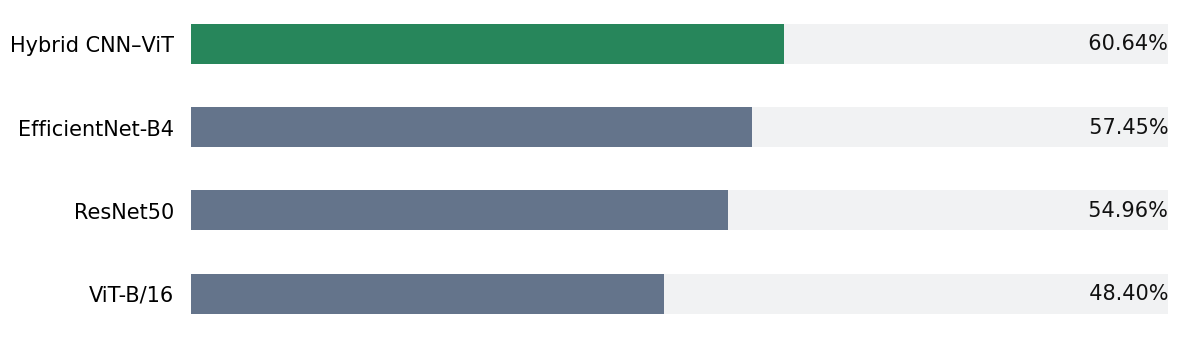

In [30]:

import matplotlib.pyplot as plt

models = [
    "Hybrid CNN–ViT",
    "EfficientNet-B4",
    "ResNet50",
    "ViT-B/16"
]

accuracies = [60.64, 57.45, 54.96, 48.40]

fig, ax = plt.subplots(figsize=(12, 3.6))

# Highlight the best model in green
colors = ["#27865B", "#64748B", "#64748B", "#64748B"]

bars = ax.barh(
    models,
    [100] * len(models),
    color="#F1F2F3",
    height=0.48
)

# Overlay accuracy bars
for i, (accuracy, color) in enumerate(zip(accuracies, colors)):
    ax.barh(
        i, accuracy,
        color=color,
        height=0.48
    )
    ax.text(
        100, i, f"  {accuracy:.2f}%",
        va="center",
        ha="right",
        fontsize=15,
        fontweight="medium",
        color="#111111"
    )

ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xticks([])
ax.tick_params(axis="y", length=0, labelsize=15, pad=12)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_facecolor("white")
fig.patch.set_facecolor("white")

plt.tight_layout(pad=1.5)
plt.show()


In [31]:

import os
import pandas as pd
from google.colab import files
from IPython.display import display

# Test accuracies obtained from your evaluation
results = pd.DataFrame({
    "Model": [
        "Hybrid CNN-ViT",
        "EfficientNet-B4",
        "ResNet50",
        "ViT-B/16"
    ],
    "Test Accuracy (%)": [
        60.64,
        57.45,
        54.96,
        48.40
    ]
})

results = results.sort_values(
    "Test Accuracy (%)",
    ascending=False
).reset_index(drop=True)

results.insert(0, "Rank", range(1, len(results) + 1))

print("MODEL PERFORMANCE COMPARISON")
display(results)

# Download the best saved model checkpoint
best_model_path = "/content/best_hybrid_cnn_vit.pth"

if os.path.exists(best_model_path):
    print("\nBest model: Hybrid CNN-ViT")
    print(f"Test accuracy: {results.iloc[0]['Test Accuracy (%)']:.2f}%")
    print(f"Checkpoint size: {os.path.getsize(best_model_path) / (1024**2):.2f} MB")
    files.download(best_model_path)
else:
    print("Checkpoint not found:", best_model_path)
    print("Please check that the training checkpoint still exists in this Colab session.")


MODEL PERFORMANCE COMPARISON


,Rank,Model,Test Accuracy (%)
0,1,Hybrid CNN-ViT,60.64
1,2,EfficientNet-B4,57.45
2,3,ResNet50,54.96
3,4,ViT-B/16,48.40



Best model: Hybrid CNN-ViT
Test accuracy: 60.64%
Checkpoint size: 400.03 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>